In [9]:
import numpy as np

class GridWorld:
    def __init__(self, shape=(5,5), start_state=(0,0), goal_state=(4,4), obstacle_states=None):
        self.shape = shape
        self.start_state = start_state
        self.goal_state = goal_state
        self.obstacle_states = set(obstacle_states) if obstacle_states else set()
        self.current_state = start_state
        self.rewards = -1 * np.ones(shape) # Default reward for each step
        self.rewards[goal_state] = 10 # Reward for reaching the goal

        for obs in self.obstacle_states:
            self.rewards[obs] = -10 # Penalty for hitting obstacles

        self.actions = {'up': 0, 'down': 1, 'left': 2, 'right': 3}
        self.action_space_size = len(self.actions)
        self.state_space_size = shape[0] * shape[1]

    def _is_valid_state(self, state):
        row, col = state
        return 0 <= row < self.shape[0] and 0 <= col < self.shape[1] and state not in self.obstacle_states

    def step(self, action):
        if self.current_state == self.goal_state:
            return self.current_state, 0, True, {}

        row, col = self.current_state
        new_row, new_col = row, col

        if action == self.actions['up']: new_row -= 1
        elif action == self.actions['down']: new_row += 1
        elif action == self.actions['left']: new_col -= 1
        elif action == self.actions['right']: new_col += 1

        new_state = (new_row, new_col)

        if self._is_valid_state(new_state):
            self.current_state = new_state
        # If invalid, stay in the current state (with a penalty if it's an obstacle)

        reward = self.rewards[self.current_state]
        done = (self.current_state == self.goal_state)

        return self.current_state, reward, done, {}

    def reset(self):
        self.current_state = self.start_state
        return self.current_state

    def render(self):
        grid = np.zeros(self.shape, dtype=str)
        grid[:] = ' . '
        grid[self.goal_state] = ' G '
        for obs in self.obstacle_states:
            grid[obs] = ' X '
        grid[self.current_state] = ' A '
        print('\n'.join([''.join(row) for row in grid]))


In [7]:
def random_policy(env):
    # Return a random action from the environment's action space
    return np.random.choice(list(env.actions.values()))


In [8]:
def monte_carlo_prediction(env, policy, num_episodes, gamma=0.99):
    # Initialize value function and counts for each state
    # Using a dictionary for V and N for sparse state spaces, or numpy array if states are easily indexed
    V = np.zeros(env.shape) # Value function V(s)
    N = np.zeros(env.shape) # Count of visits to each state N(s)

    for episode in range(num_episodes):
        episode_states_actions_rewards = []
        env.reset()
        current_state = env.current_state
        done = False

        # Generate an episode
        while not done:
            action = policy(env)
            next_state, reward, done, _ = env.step(action)
            episode_states_actions_rewards.append((current_state, action, reward))
            current_state = next_state
            if done: # If the episode ends, stop.
                break

        # Calculate returns and update value function
        G = 0 # Return
        visited_states = set() # To implement First-Visit MC

        # Iterate backwards through the episode to calculate returns efficiently
        for t in reversed(range(len(episode_states_actions_rewards))):
            state, action, reward = episode_states_actions_rewards[t]
            G = gamma * G + reward

            # Check for first visit
            if state not in visited_states:
                N[state] += 1
                V[state] += (G - V[state]) / N[state] # Incremental update rule
                visited_states.add(state)

    return V


Running Monte Carlo Prediction for 1000 episodes...

Estimated State Values (V):
[[-28.49699548 -26.33053006 -19.82606221 -20.58334957 -22.28814277]
 [-27.45587525   0.         -16.33835325 -18.1850953  -15.08533962]
 [-21.26287013 -20.16856245 -11.98425657   0.          -7.57004754]
 [-22.68720694   0.          -4.51209951  -0.4003048    2.65230625]
 [-20.61799455 -13.74950148  -5.01230773   2.20909751   0.        ]]


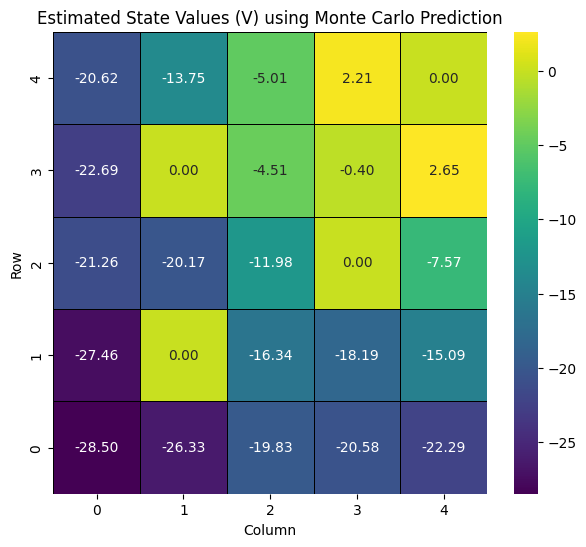

In [11]:
# Create a new environment instance for cleaner episodes
env_mc = GridWorld(
    shape=(5,5),
    start_state=(0,0),
    goal_state=(4,4),
    obstacle_states=[(1,1), (2,3), (3,1)]
)

num_episodes = 1000
gamma = 0.99 # Discount factor

print(f"Running Monte Carlo Prediction for {num_episodes} episodes...")
estimated_values = monte_carlo_prediction(env_mc, random_policy, num_episodes, gamma)

print("\nEstimated State Values (V):")
print(estimated_values)

# Optional: Visualize the value function
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 6))
sns.heatmap(
    estimated_values,
    annot=True,
    fmt=".2f",
    cmap="viridis",
    cbar=True,
    linewidths=.5,
    linecolor='black'
)
plt.title("Estimated State Values (V) using Monte Carlo Prediction")
plt.xlabel("Column")
plt.ylabel("Row")
plt.gca().invert_yaxis() # Invert y-axis to match gridworld (row 0 at top)
plt.show()
